In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    brier_score_loss,
    average_precision_score,
    precision_recall_curve
)


# Load logistic regression model weights

In [ ]:
# Load XGBoost probabilities
lr_real = np.load(r"...../proba/LR_real_proba.npy")
lr_smote = np.load(r".../proba/LR_smote_proba.npy")
lr_syn = np.load(r"...../proba/LR_synthetic_proba.npy")
lr_smote_syn = np.load(r"..../proba/LR_smote_synthetic_proba.npy")
y_test = np.load(r"......./proba/y_test_real.npy")

print("Real_test:", len(y_test))
print("Real:", len(lr_real))
print("SMOTE:", len(lr_smote))
print("Synthetic:", len(lr_syn))
print("SMOTE + Synthetic:", len(lr_smote_syn))

In [ ]:
models_lr = {
    "Real": lr_real,
    "SMOTE": lr_smote,
    "Synthetic": lr_syn,
    "SMOTE + Synthetic": lr_smote_syn
}

# Calibration curve

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

# Perfect calibration line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Perfect calibration"
)

# Plot all four training strategies
for name, probabilities in models_lr.items():

    prob_true, prob_pred = calibration_curve(
        y_test,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    brier = brier_score_loss(
        y_test,
        probabilities
    )

    plt.plot(
        prob_pred,
        prob_true,
        marker="o",
        linewidth=2,
        label=f"{name} (Brier = {brier:.3f})"
    )

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Event Frequency")

plt.title("Calibration Curves - Logistic Regression")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.legend(frameon=False)

plt.tight_layout()
plt.show()

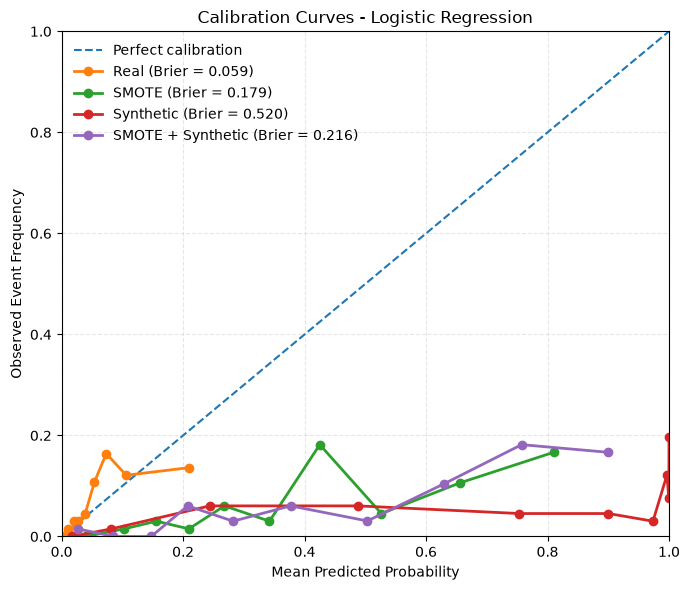

# Brier scores

In [ ]:
from sklearn.metrics import brier_score_loss

print("LR Real:",
      brier_score_loss(y_test, lr_real))

print("LR SMOTE:",
      brier_score_loss(y_test, lr_smote))

print("LR Synthetic:",
      brier_score_loss(y_test, lr_syn))

print("LR SMOTE + Synthetic:",
      brier_score_loss(y_test, lr_smote_syn))

# Precision-Recall Curves

In [ ]:
# ---------------------------------------------------
# Combined Precision-Recall Curves - XGBoost
# ---------------------------------------------------

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

import numpy as np
import matplotlib.pyplot as plt

# NEC prevalence in held-out real test set
prevalence = np.mean(y_test)

# Define models
models = {
    "Real (TRTR)": lr_real,
    "SMOTE": lr_smote,
    "Synthetic (TSTR)": lr_syn,
    "SMOTE + Synthetic": lr_smote_syn
}

plt.figure(figsize=(7, 6))

# Plot PR curve for each training strategy
for name, probabilities in models.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    auprc = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AUPRC = {auprc:.3f})"
    )

# NEC prevalence = no-skill PR baseline
plt.axhline(
    y=prevalence,
    color="#8B0000",
    linestyle=":",
    linewidth=2.5,
    label=f"NEC prevalence ({prevalence:.1%})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision–Recall Curves - Logistic Regression")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.legend(
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()

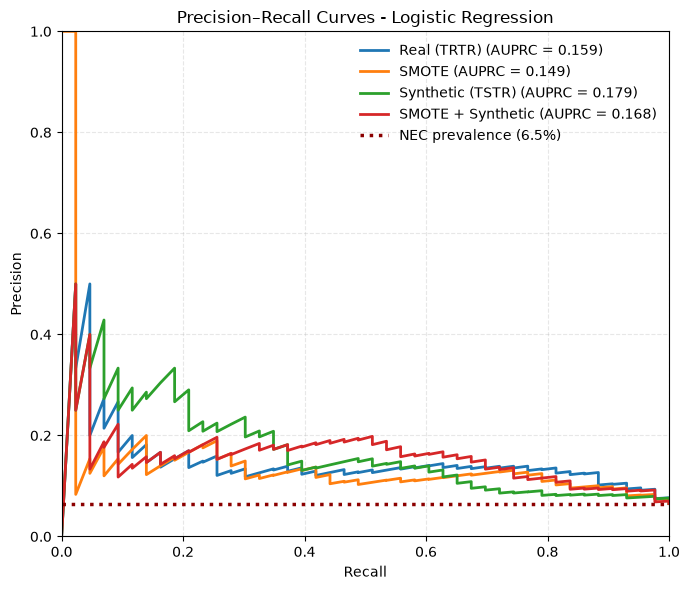

In [ ]:
print("LR AUPRC")
print("-------------------------")

for name, probabilities in models_lr.items():

    auprc = average_precision_score(
        y_test,
        probabilities
    )

    print(f"{name}: {auprc:.3f}")

print(f"NEC prevalence: {prevalence:.3f}")

# Decision Curve analysis

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def decision_curve(y_true, y_prob, thresholds):
    """
    Calculate net benefit across threshold probabilities.
    """
    
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob)

    n = len(y_true)
    net_benefits = []

    for pt in thresholds:

        # Classify as positive if predicted probability >= threshold
        y_pred = (y_prob >= pt).astype(int)

        TP = np.sum((y_pred == 1) & (y_true == 1))
        FP = np.sum((y_pred == 1) & (y_true == 0))

        net_benefit = (
            TP / n
            - (FP / n) * (pt / (1 - pt))
        )

        net_benefits.append(net_benefit)

    return np.array(net_benefits)

In [ ]:
def treat_all_net_benefit(y_true, thresholds):

    y_true = np.asarray(y_true)

    prevalence = np.mean(y_true)

    return (
        prevalence
        - (1 - prevalence)
        * (thresholds / (1 - thresholds))
    )

In [ ]:
# Choose thresholds
thresholds = np.arange(
    0.01,
    0.31,
    0.01
)

In [ ]:
# ---------------------------------------------
# Logistic Regression DCA
# ---------------------------------------------

lr_models = {
    "Real": lr_real,
    "SMOTE": lr_smote,
    "Synthetic": lr_syn,
    "SMOTE + Synthetic": lr_smote_syn
}

plt.figure(figsize=(8, 6))

for name, probabilities in lr_models.items():

    nb = decision_curve(
        y_test,
        probabilities,
        thresholds
    )

    plt.plot(
        thresholds,
        nb,
        linewidth=2,
        label=name
    )


# Treat all
nb_all = treat_all_net_benefit(
    y_test,
    thresholds
)

plt.plot(
    thresholds,
    nb_all,
    linestyle="--",
    linewidth=2,
    label="Treat all"
)


# Treat none
plt.axhline(
    y=0,
    linestyle=":",
    linewidth=2,
    label="Treat none"
)


plt.xlabel("Threshold Probability")
plt.ylabel("Net Benefit")

plt.title("Decision Curve Analysis – Logistic Regression")

plt.legend(frameon=False)

plt.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

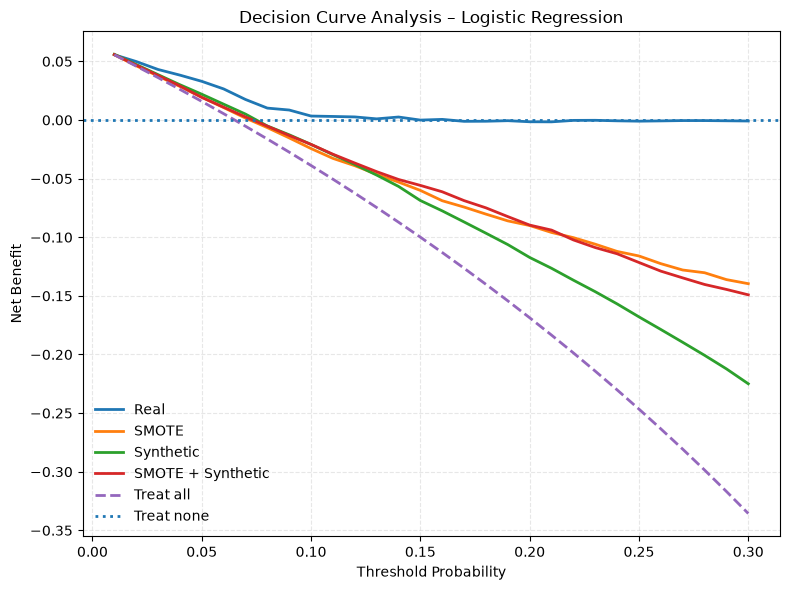

# Load XGBoost model weights

In [ ]:
# Load XGBoost probabilities
xgb_real = np.load(r"..../proba/XGB_real_proba.npy")
xgb_smote = np.load(r"...proba/XGB_smote_proba.npy")
xgb_syn = np.load(r".../proba/XGB_synthetic_proba.npy")
xgb_smote_syn = np.load(r".../proba/XGB_smote_synthetic_proba.npy")
y_test = np.load(r".../proba/y_test_real.npy")

print("Real_test:", len(y_test))
print("Real:", len(xgb_real))
print("SMOTE:", len(xgb_smote))
print("Synthetic:", len(xgb_syn))
print("SMOTE + Synthetic:", len(xgb_smote_syn))

In [ ]:
models = {
    "Real": xgb_real,
    "SMOTE": xgb_smote,
    "Synthetic": xgb_syn,
    "SMOTE + Synthetic": xgb_smote_syn
}

# Calibration curve

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

# Perfect calibration line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Perfect calibration"
)

# Plot all four training strategies
for name, probabilities in models.items():

    prob_true, prob_pred = calibration_curve(
        y_test,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    brier = brier_score_loss(
        y_test,
        probabilities
    )

    plt.plot(
        prob_pred,
        prob_true,
        marker="o",
        linewidth=2,
        label=f"{name} (Brier = {brier:.3f})"
    )

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Event Frequency")

plt.title("Calibration Curves - XGBoost")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.legend(frameon=False)

plt.tight_layout()
plt.show()

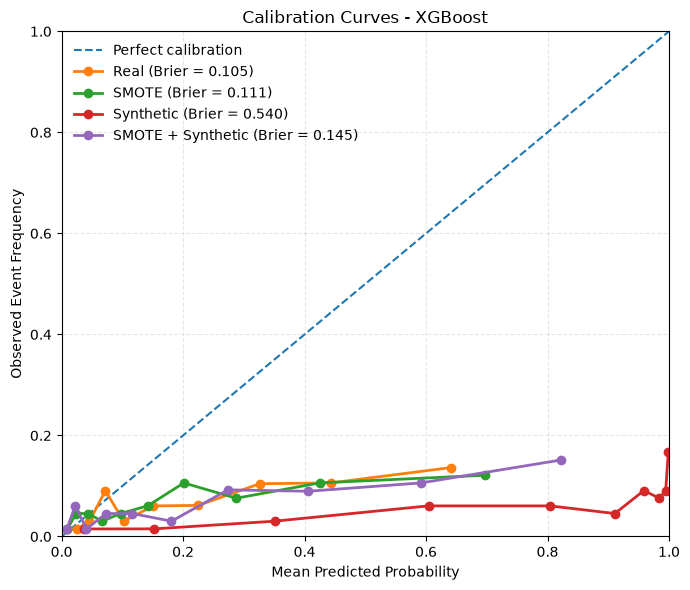

In [ ]:
# Brier scores

In [ ]:
from sklearn.metrics import brier_score_loss

print("XGB Real:",
      brier_score_loss(y_test, xgb_real))

print("XGB SMOTE:",
      brier_score_loss(y_test, xgb_smote))

print("XGB Synthetic:",
      brier_score_loss(y_test, xgb_syn))

print("XGB SMOTE + Synthetic:",
      brier_score_loss(y_test, xgb_smote_syn))

# Precision-Recall curves

In [ ]:
# ---------------------------------------------------
# Combined Precision-Recall Curves - XGBoost
# ---------------------------------------------------

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

import numpy as np
import matplotlib.pyplot as plt

# NEC prevalence in held-out real test set
prevalence = np.mean(y_test)

# Define models
models = {
    "Real (TRTR)": xgb_real,
    "SMOTE": xgb_smote,
    "Synthetic (TSTR)": xgb_syn,
    "SMOTE + Synthetic": xgb_smote_syn
}

plt.figure(figsize=(7, 6))

# Plot PR curve for each training strategy
for name, probabilities in models.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    auprc = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AUPRC = {auprc:.3f})"
    )

# NEC prevalence = no-skill PR baseline
plt.axhline(
    y=prevalence,
    color="#8B0000",
    linestyle=":",
    linewidth=2.5,
    label=f"NEC prevalence ({prevalence:.1%})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision–Recall Curves - XGBoost")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.legend(
    frameon=False,
    loc="upper right"
)

plt.tight_layout()
plt.show()

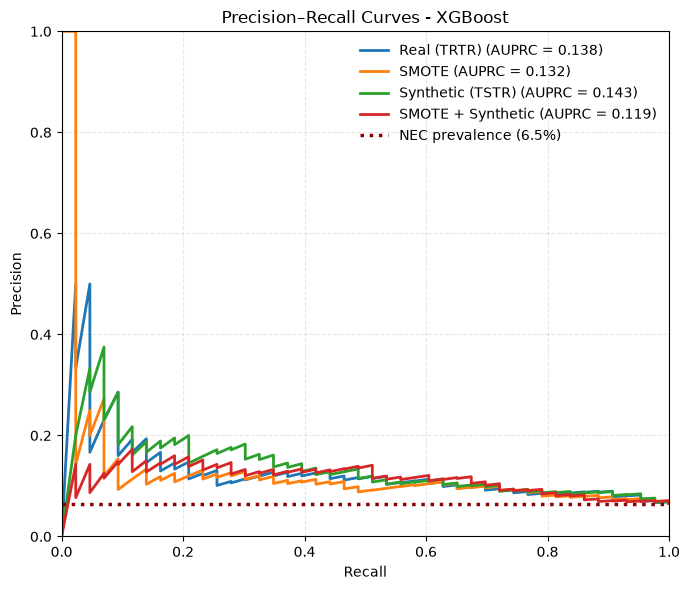

In [ ]:
print("XGBoost AUPRC")
print("-------------------------")

for name, probabilities in models.items():

    auprc = average_precision_score(
        y_test,
        probabilities
    )

    print(f"{name}: {auprc:.3f}")

print(f"NEC prevalence: {prevalence:.3f}")

# Decision Curve Analysis

In [ ]:
# ---------------------------------------------
# XGBoost DCA
# ---------------------------------------------

xgb_models = {
    "Real": xgb_real,
    "SMOTE": xgb_smote,
    "Synthetic": xgb_syn,
    "SMOTE + Synthetic": xgb_smote_syn
}

plt.figure(figsize=(8, 6))

for name, probabilities in xgb_models.items():

    nb = decision_curve(
        y_test,
        probabilities,
        thresholds
    )

    plt.plot(
        thresholds,
        nb,
        linewidth=2,
        label=name
    )


# Treat all
nb_all = treat_all_net_benefit(
    y_test,
    thresholds
)

plt.plot(
    thresholds,
    nb_all,
    linestyle="--",
    linewidth=2,
    label="Treat all"
)


# Treat none
plt.axhline(
    y=0,
    linestyle=":",
    linewidth=2,
    label="Treat none"
)


plt.xlabel("Threshold Probability")
plt.ylabel("Net Benefit")

plt.title("Decision Curve Analysis – XGBoost")

plt.legend(frameon=False)

plt.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

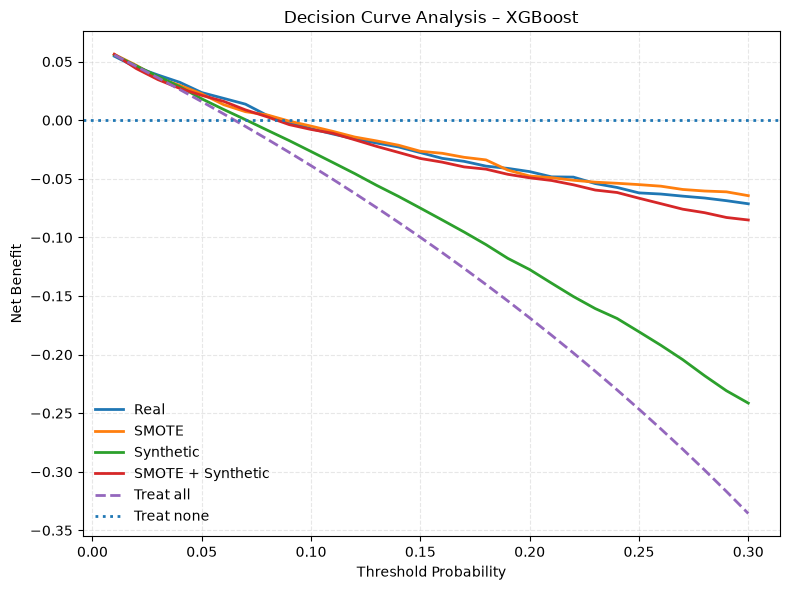